# 02 — Neural Network-Based Anomaly Detection in Industrial IoT

**`Topic:`** ***Distributed Big Data processing for neural network-based anomaly detection in the Industrial Internet of Things (IIoT).***

**`Module: Advanced Data Analytics — Neural Networks`**

### Module Learning Outcomes (MLOs)

- **MLO 1:** In this module, we discuss the theoretical foundations and applications of various types of neural networks, covering:
- Architectures
- Characteristics
- Advantages
- Limitations.

- **MLO 2:** In this module, we examine which neural network architecture is best suited for detecting malicious activity (cyberattacks) within Industrial Internet of Things (IIoT) network traffic, taking into account:

- Predictive performance
- Computational complexity
- Application requirements.

### Notebook Objective

In this notebook, we conduct experiments on detecting malicious traffic in *Industrial Internet of Things* (IIoT) environments, using the Edge-IIoTset dataset and artificial neural network models.

For this analysis, we employ a supervised binary classification approach, where the `Attack_label` variable identifies traffic records as either normal (`0`) or malicious (`1`).

The experiments are designed to explore different neural network configurations and classification strategies, specifically investigating their impact on:
- Attack detection capability
- The occurrence of false positives and false negatives
- Computational cost.

### Experiment Organization

- **E1 — Baseline Neural Network:** In this experiment, we develop and evaluate a *Multilayer Perceptron* (MLP) neural network to serve as a baseline model.

- **E2 — Enhanced Neural Network:** In this experiment, we evaluate a more complex MLP architecture, incorporating additional layers and *Dropout* regularization. - **E3 — Decision Threshold Optimisation:** In this experiment, we investigate the impact of different classification thresholds on:
- *precision*
- *recall*
- *F1-score*
- False positive and false negative rates.

### Methodological Scope

As previously mentioned, this notebook aims to evaluate the training and predictive performance of neural networks in a single-machine computational environment, using Google Colab.

> The objective of this notebook is to assess the effectiveness of neural networks in detecting malicious traffic and to analyze the relationships between architecture, predictive performance, and computational cost, without attributing the results to distributed training techniques.

### Execution Instructions

Begin by running the cells for environment setup and dataset acquisition. Then, execute the remaining cells sequentially, following the steps for data preparation, training, validation, and model evaluation.

# 1.1 Research Question

> **How ​​do different artificial neural network architectures and classification threshold optimization strategies influence the predictive performance and computational cost of detecting malicious traffic in Industrial Internet of Things (IIoT) environments?**


This research aims to analyze the ability of deep learning models to identify patterns associated with malicious activities in industrial networks, while also considering the differences between various **neural architectures** and **classification strategies**.

> **This work also seeks to understand the trade-offs between the ability to identify attacks, the reduction of false alarms, and the computational resources required to train the models.**

# 1.2 Specific Research Objectives

1. **Phase 1 – Investigate the theoretical foundations of artificial neural networks:** We examine various architectures—such as Multilayer Perceptrons (MLP), Convolutional Neural Networks (CNN), Recurrent Neural Networks (RNN/LSTM), and Autoencoders—analyzing their characteristics, advantages, and limitations in the context of anomaly detection.

2. **Phase 2 – Analyze and prepare the Edge-IIoTset dataset** for the application of supervised models: Before conducting the experiments, we process the data—selecting numerical features, handling missing values, assessing class distribution, and standardizing the dataset.

3. **Phase 3 – Develop a baseline neural model (Experiment E1):** We employ an MLP architecture to establish a performance benchmark for the binary detection of malicious traffic.

4. **Phase 4 – Implement and evaluate a more complex neural architecture (Experiment E2):** We incorporate additional layers and regularization mechanisms, such as *Dropout*, to investigate potential improvements in the model's generalization capability. 5. **Phase 5 - Comparing the performance of models E1 and E2** using classification metrics—specifically, well-established ones such as accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.

6. **Phase 6 - Evaluating the computational cost of the investigated architectures**, taking into account training time and the trade-off between model complexity and gains in predictive performance.


# 1.3 Scope of the investigation

Accordingly, this work focuses on the application and evaluation of deep learning techniques for the supervised detection of malicious traffic in Industrial Internet of Things (IIoT) networks.

The present work seeks to implement the following stages.:

- Data analysis and preparation for supervised learning.
- Theoretical foundation and selection of neural architectures.
- Development and training of MLP models.
- Comparison of different architectural configurations.
- Optimization of the decision threshold.
- Evaluation of predictive performance and computational cost.
- Critical discussion of the results and experimental limitations.

The experiments conducted utilize the Edge-IIoTset dataset, introduced by Ferrag et al. (2022). This work employs the same reference variable used in our own experiments: the `Attack_label` variable, which serves as the basis for the binary classification of network records as either normal or malicious.

Considering the tabular nature of the attributes, the most sensible choice is the MLP architecture; with this, we seek to investigate non-linear relationships between network traffic characteristics and classification labels.

## 0. Colab environment

In [1]:
%pip -q install tensorflow scikit-learn pyarrow

In [2]:

!pip -q install kagglehub


### 3.1 Dataset Acquisition Using KaggleHub

**Objective:** To obtain the Edge-IIoTset dataset from a public repository, ensuring access to the records required for the implementation and evaluation of neural network models.

In this work, we use the **Edge-IIoTset** dataset, developed by Ferrag et al. (2022). This dataset contains network traffic characteristics and records associated with various categories of cyberattacks within IoT and Industrial IoT (IIoT) environments.

To acquire the data, we utilized the `kagglehub` Python library, which allows for accessing and retrieving datasets hosted on the Kaggle platform. An advantage of this approach is that it eliminates the need to store files locally, facilitating the reproduction of the procedure across different Google Colab sessions.

We performed the data acquisition using the `kagglehub.dataset_download()` method, specifying the repository identifier:

> `mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot`

Once the dataset was retrieved, we used the `pathlib` library—specifically the `rglob("*.csv")` method—to recursively locate the CSV files required for our experiments.

> -> **This step is crucial because the repository contains various files, each associated with specific categories of cyberattacks.**

**Results**

The execution was completed successfully, and KaggleHub made the dataset available in the following directory:

`/kaggle/input/edgeiiotset-cyber-security-dataset-of-iot-iiot`

The system indicated that the Colab cache was utilized to accelerate access to the files.

This procedure also enabled the identification of several CSV files linked to malicious activities, including records of DDoS attacks, XSS, and other categories present in the repository.

In [3]:

import kagglehub
from pathlib import Path

dataset_path = kagglehub.dataset_download(
    "mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot"
)

print("Dataset downloaded to:", dataset_path)

csv_files = list(Path(dataset_path).rglob("*.csv"))

print("\nAvailable CSV files:")
for file in csv_files:
    print(file.name, "->", file)


Download already complete (1746605436 bytes).
Extracting files...
Dataset downloaded to: /root/.cache/kagglehub/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5

Available CSV files:
ML-EdgeIIoT-dataset.csv -> /root/.cache/kagglehub/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/Edge-IIoTset dataset/Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv
DNN-EdgeIIoT-dataset.csv -> /root/.cache/kagglehub/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv
Ransomware_attack.csv -> /root/.cache/kagglehub/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/Edge-IIoTset dataset/Attack traffic/Ransomware_attack.csv
OS_Fingerprinting_attack.csv -> /root/.cache/kagglehub/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/Edge-IIoTset dataset/

### 3.2 Identification of the main file and environment configuration

**Objective:** To identify the consolidated Edge-IIoTset file intended for machine learning applications and to configure the necessary directories for executing and storing the experiments.

Following data acquisition, a search was conducted for the file `DNN-EdgeIIoT-dataset.csv`, which serves as the primary source for the malicious traffic detection experiments.

This identification was performed by comparing the names of the CSV files found in the repository against the expected name of the consolidated file.

The code also includes an existence check, utilizing the `FileNotFoundError` exception in the event that the file cannot be located. This procedure ensures that execution is halted before data processing begins if the expected source is unavailable.

Once the file was identified, its path was stored in the variable `DATASET_PATH`, centralizing the reference to the data source and avoiding the need to repeatedly enter absolute paths throughout the notebook.

Additionally, the following directory was configured:

`/content/iiot_ca_results`

This directory will be used to store experimental results, including metric tables, intermediate files, and plots generated during the investigation.

A random seed, `SEED = 42`, was also defined to support the reproducibility of stochastic operations in subsequent stages.

**Result obtained**

Through this procedure, we identified the following file:

`Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv`

The verification performed using `Path(DATASET_PATH).is_file()` returned:

`Dataset exists: True`

This result confirms that the selected file is accessible within the execution environment.

**Methodological considerations**

Centralizing file paths and defining a random seed contribute to the organization and consistency of the experiments. The files stored in `/content` are temporary and will be deleted when the Google Colab session is restarted. For this reason, final results should be saved to persistent storage.

In [4]:

matches = [
    file for file in csv_files
    if file.name == "DNN-EdgeIIoT-dataset.csv"
]

if not matches:
    raise FileNotFoundError(
        "DNN-EdgeIIoT-dataset.csv was not found. "
        "Check the CSV files listed above."
    )

DATASET_PATH = str(matches[0])

OUT = Path("/content/iiot_ca_results")
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42

print("Selected dataset:", DATASET_PATH)
print("Dataset exists:", Path(DATASET_PATH).is_file())


Selected dataset: /root/.cache/kagglehub/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot/versions/5/Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv
Dataset exists: True


### 3.3 Initial dataset inspection and identification of classification variables

**Objective:** To examine the initial structure of the dataset, determine its dimensions, and locate potential target variables for supervised classification experiments.

Following the previous step, in which we identified the main file, we performed an exploratory read using the `pandas` library via the `pd.read_csv()` function.

In this initial phase, we limited the read operation to the first 1,000 records using the `nrows=1000` parameter. This allowed for an initial inspection of the data, enabling us to understand the dataset without loading the entire collection into memory.

We also used the `low_memory=False` parameter to disable fragmented type inference during the read process. It is important to note, however, that because the read was limited to 1,000 records, the data types identified in this sample may not represent all values ​​present in the complete dataset.

**Structural inspection results**

The execution yielded the following:

- **Records analyzed:** 1,000.
- **Number of attributes:** 63.
- **Sample dimensions:** `(1000, 63)`.

An analysis of the first row revealed attributes related to network traffic, including protocol information and packet characteristics, such as `frame.time`, `ip.src_host`, `ip.dst_host`, `arp.opcode`, and `icmp.checksum`.

> These attributes represent information that may be relevant for characterizing communication patterns and identifying behaviors associated with malicious activity.

**Identification of classification variables**

Subsequently, we conducted an exploratory search of the column names using keywords widely recognized in the literature: `attack`, `label`, and `class`. The choice of these terms was motivated by the terminology used in cybersecurity datasets and supervised classification. For instance, Ferrag et al. (2022) use the variables `Attack_label` and `Attack_type` in the Edge-IIoTset, while Moustafa and Slay (2015) employ the variables `label` and `attack_cat` in the UNSW-NB15 dataset.

> **This is a crucial step, as it allows us to identify potential attributes relevant to classification without having to manually inspect every column name.**

In the Edge-IIoTset, the variables of interest are:

- `Attack_label`: a binary classification variable used to distinguish between normal and malicious traffic.
- `Attack_type`: a categorical variable that identifies the nature or category of the traffic, including the various types of attacks.

**Methodological considerations**

> Identifying such variables is essential for defining the supervised learning problem and for separating predictor attributes from the information used as a reference for classification.

In this study, the `Attack_label` variable will serve as the target variable for the neural models, while `Attack_type` may contribute to the exploratory characterization of the attack categories.

In [5]:

import pandas as pd

# Read a small sample to avoid loading the entire CSV
df_preview = pd.read_csv(
    DATASET_PATH,
    nrows=1000,
    low_memory=False
)

print("Dataset preview shape:", df_preview.shape)
print("Number of columns:", len(df_preview.columns))

display(df_preview.head())

print("\nClassification columns:")
print([
    col for col in df_preview.columns
    if "attack" in col.lower()
    or "label" in col.lower()
    or "class" in col.lower()
])


Dataset preview shape: (1000, 63)
Number of columns: 63


,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,2021 11:44:10.081753000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
1,2021 11:44:10.162218000,192.168.0.101,192.168.0.128,0,0.0,0.0,0,0.0,0.0,0.0,...,4.0,MQTT,0,0.0,4.0,0.0,0.0,0.0,0,Normal
2,2021 11:44:10.162271000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
3,2021 11:44:10.162641000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
4,2021 11:44:10.166132000,192.168.0.101,192.168.0.128,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,Temperature_and_Humidity,24.0,0.0,0.0,0.0,0.0,0,Normal



Classification columns:
['Attack_label', 'Attack_type']


# 3.4 — Stratified Sampling and Memory-Efficient Data Selection

## 3.4.1 Objective and Methodological Rationale

In this stage, our objective is to implement a stratified random sampling procedure to select a representative subset of samples from the Edge-IIoTset dataset. We aim to preserve the original proportion between normal and malicious traffic, while also avoiding the need to load the entire CSV file into memory at once.

> As previously mentioned, the Edge-IIoTset was developed by Ferrag et al. (2022) to support cybersecurity research in IoT and Industrial IoT (IIoT) environments. The dataset contains various categories of attacks and includes an `Attack_label` variable, which allows for the distinction between normal traffic records (`0`) and malicious traffic records (`1`).

This strategy is advantageous because it ensures:

1. **Class Representativeness:** Selecting only the initial records from a file can introduce bias, especially if the data is ordered by category or traffic type.
2. **Computational Resource Management:** Selecting a subset reduces the memory required for training experiments.
3. **Experimental Consistency:** Using the same sample across experiments E1, E2, and E3 allows for the comparison of models under equivalent conditions.

The importance of stratification when evaluating classifiers is discussed by Kohavi (1995), who investigated validation strategies and performance estimation. Although the author focused primarily on cross-validation methods, his research provides a conceptual basis for preserving class composition.

To implement this strategy, we developed a function called `stratified_csv_sample()`, which combines:
- incremental reading using pandas;
- proportional quota calculation;
- random selection without replacement, based on the hypergeometric distribution. ## 3.4.2 Initialization of the random number generator

**Implemented code:**

`rng = np.random.default_rng(seed)`

The first operation performed by the function initializes a pseudo-random number generator using the NumPy library:

- `seed` – This parameter allows for control over the sequence of generated numbers, contributing to the reproducibility of the selection process.

In this study, we used a fixed value of `seed=42`, which carries no specific statistical significance.


Setting a fixed seed is important because subsequent experiments depend on the composition of the selected sample. It should be noted that, although the selection is random, it follows a sequence determined by the seed; in other words, we can test different architectures, but these architectures will be trained using the same samples, providing a more reliable basis for comparison.
- If each architecture were trained using different samples, it would be more difficult to determine whether performance differences arose from the architecture itself or from the characteristics of the selected records.

This decision relates to the need for consistency in the experimental evaluation of classifiers, as discussed by Kohavi (1995).

However, Kohavi does not establish the value 42 as a standard. The specific choice of this seed is an implementation decision unique to this project. ## 3.4.3 First pass: incremental reading and class counting

**Implemented code:**

```python
counts = pd.Series(dtype='int64')

for chunk in pd.read_csv(
path,
usecols=[label],
chunksize=chunksize,
low_memory=False
):
counts = counts.add(
chunk[label].value_counts(),
fill_value=0
)

counts = counts.astype('int64')
```

The purpose of this code block is to determine the number of records belonging to each class in the original dataset:

- `pd.read_csv()` performs an incremental read of the file, dividing it into chunks defined by the `chunksize` parameter.

- `usecols=[label]` restricts the read operation to the classification variable, avoiding the need to load attributes that are not required during this stage.

- `value_counts()` tallies the records for each class within the current chunk, while `counts.add()` accumulates these counts across successive read operations.

- `fill_value=0` ensures that counts can be combined even when a specific class is absent from one of the chunks.

- `int64` ensures that the counts are represented as integer values.

**Methodological rationale**

> Incremental reading was chosen to reduce memory consumption when analyzing a large-volume file.

> This approach makes it possible to determine the global class distribution without having to store all observations from the CSV file in memory simultaneously.

## 3.4.4 Population Size Verification

**Implemented code:**

```python
total = int(counts.sum())

if n_rows > total:
raise ValueError(
f'Requested {n_rows:,}, '
f'but CSV has {total:,} rows'
)
```

After counting the total number of records in each class (Normal and Attack), it is possible to determine the total number of entries available in the dataset.
- This information is necessary to calculate the proportion of each class and to define how many records should be selected during the stratified sampling process.

Next, the code checks whether the quantity requested in `n_rows` exceeds the number of available records.

If this condition is met, execution is halted by raising a `ValueError` exception.

## 3.4.5 Proportional Calculation of Sampling Quotas

**Implemented code:**

```python
expected = counts * (n_rows / total)

quotas = np.floor(expected).astype('int64')

remainder = n_rows - int(quotas.sum())

for cls in (
expected - quotas
).sort_values(ascending=False).index[:remainder]:
quotas.loc[cls] += 1
```

This code block determines how many records from each class should make up the final sample.

Initially, the algorithm calculates the expected number of records per class by multiplying its original frequency by the total sampling fraction.

The expected quantity for a class can be represented as:

\[
E_c=N_c\frac{n}{N}
\]

Where:

- \(E_c\) represents the expected number of records for the class.
- \(N_c\) represents the original number of records for the class.
- \(n\) represents the desired sample size.
- \(N\) represents the total number of records in the dataset. Since the number of selected records must be an integer, `np.floor()` is used to initially round the quotas down.

However, this rounding may result in a total sum that is less than the requested size.

For this reason, the algorithm calculates the difference using the `remainder` variable and distributes the remaining records among the classes that had the largest fractional parts.

**Methodological justification**

> The use of proportional quotas was adopted to approximately preserve the original distribution between normal and malicious traffic.

> This decision is related to the binary structure of the Edge-IIoTset, as presented by Ferrag et al. (2022).


## 3.4.6 Preparation of control structures and feature selection

**Implemented code:**

```python
remaining_population = counts.to_dict()
remaining_quota = quotas.to_dict()

pieces = []

usecols = (
list(dict.fromkeys((columns or []) + [label]))
if columns is not None
else None
)
```

After defining the quotas, the algorithm initializes structures responsible for controlling the selection process.

- `remaining_population` – stores the number of records for each class that have not yet been processed.

- `remaining_quota` – represents how many records from each class still need to be selected.

These structures are updated during the second pass through the file, allowing the algorithm to account for selections made previously.

- `pieces` – used to temporarily store the subsets selected from each block.

- `usecols` parameter – determines which columns will be loaded.
## 3.4.7 Second pass: grouping and random selection by class

**Implemented code:**

```python
for chunk in pd.read_csv(
path,
usecols=usecols,
chunksize=chunksize,
low_memory=False
):
for cls, group in chunk.groupby(
label,
sort=False
):
pop = int(remaining_population[cls])
quota = int(remaining_quota[cls])
available = len(group)
```

The second pass through the file performs the actual selection of records.

As in the first stage, the data is read incrementally, using blocks of a size defined by `chunksize`.

However, in this stage, the attributes required for the sample are loaded.

For each class, three quantities are identified:

- `pop`: the number of remaining records for that class in the as-yet-unprocessed portion of the dataset.
- `quota`: the number of records for that class that still need to be selected.
- `available`: the number of records for that class present in the current block.

This information is necessary to determine how many records should be selected from the block.

## 3.4.8 Hypergeometric selection without replacement

**Implemented code:**

```python
selected = int(
rng.hypergeometric(
quota,
pop - quota,
available
)
)
```

The number of records selected from each block is determined using a hypergeometric distribution.

This distribution represents the number of elements of a specific category obtained in a random sample drawn from a finite population, without replacement.

Its probability mass function is expressed as:

\[
P(X=k)=
\frac{\binom{K}{k}\binom{N-K}{n-k}}
{\binom{N}{n}}
\]

Where:

- \(N\): the number of remaining records for the class. - \(K\): the number of records still required to meet the quota.
- \(n\): the number of records for a given class available in the current block.
- \(k\): the number of records randomly chosen for selection.

In the implementation, these elements correspond to `pop`, `quota`, `available`, and `selected`.

This mechanism allows for the distribution of random selection across blocks without requiring a fixed number of records per block.

Consequently, the decision-making process accounts for both the remaining population and the quota still to be filled.

**Academic Background**

The hypergeometric distribution is a standard topic in discrete probability literature, such as in the work of Johnson, Kotz, and Kemp (1992).

The broader problem of random sampling without replacement from large datasets is also explored by Vitter (1985).

It is important to note that the implementation in this notebook does not utilize the *reservoir sampling* algorithm proposed by Vitter. Instead, the code employs a two-pass strategy that combines hypergeometric sampling with random selection within each block.

This distinction ensures that the implementation is not incorrectly attributed to an algorithm other than the one actually used.

## 3.4.9 Selecting Records and Updating Quotas

**Implemented Code:**

```python
if selected:
pieces.append(
group.sample(
n=selected,
random_state=int(
rng.integers(0, 2**32 - 1)
)
)
)

remaining_population[cls] -= available
remaining_quota[cls] -= selected
```

Once the number of records to be selected is determined, the algorithm uses `group.sample()` to randomly choose the corresponding observations.

This method performs selection without replacement within the group, as this is its default behavior.

 -  `random_state`—derived from the previously initialized random number generator—allows for control over the randomness of the procedure.

The selected records are then added to the `pieces` list. Next, two control structures are updated.

 - `remaining_population` variable is reduced by the number of records processed in the block, while `remaining_quota` is reduced by the number of records actually selected.

These updates are essential for maintaining consistency across decisions made in different blocks.

Without this control, the implementation could select quantities that are incompatible with the global quotas.


## 3.4.10 Consolidation and Reordering of the Sample

**Implemented code:**

```python
result = (
pd.concat(pieces, ignore_index=True)
.sample(frac=1, random_state=seed)
.reset_index(drop=True)
)
```

Once the selection of records is complete, the algorithm gathers all the subsets stored in the `pieces` list.

The `pd.concat()` function combines these subsets into a single DataFrame.

The `ignore_index=True` argument creates a sequential index for the consolidated structure.

Then, the `sample(frac=1)` method randomly reorders all the selected records.

The `frac=1` parameter indicates that 100% of the observations are to be retained, with only their order being changed.

Finally, `reset_index(drop=True)` resets the DataFrame's index.

## 3.4.11 Validation of the final sample size

**Implemented code:**

```python
assert len(result) == n_rows
```

This final operation verifies that the number of selected records matches the requested size exactly.

This validation is necessary because the algorithm was designed to produce a sample of a fixed size.

If the condition is not met, an `AssertionError` exception will halt execution.

This check serves as a consistency control for the implementation.

However, it does not, on its own, prove that the class distribution has been preserved or that the selection is statistically representative.


## 3.4.12 Justification of function parameters

The function is defined with the following signature:

`stratified_csv_sample(path, n_rows, columns=None, label='Attack_label', chunksize=100_000, seed=42)`

**`path` — Dataset path**

Identifies the original CSV file used in the investigation.

**`n_rows` — Sample size**

Defines the exact number of records to be selected.

This parameter allows for controlling the volume of data used in experiments, taking into account available computational resources.

**`columns=None` — Attribute selection**

Allows for restricting the columns loaded during the second pass through the file.

**`label='Attack_label'` — Stratification variable**

Defines the variable used to preserve the class distribution.


**`chunksize=100_000` — Chunk size**

Determines the maximum number of records processed in each block (chunk).

This value was chosen as a practical setting to manage memory consumption; it does not represent an experimentally determined optimal size.


**`seed=42` — Randomness control**

Enables the reproduction of the selection under equivalent conditions. The value 42 was adopted for convenience, without any special statistical significance.


## 3.4.13 Importance for experiments E1, E2, and E3

Implementing stratified sampling is an essential step in preparing the neural network experiments.

By preserving, to a close approximation, the original distribution between normal and malicious traffic, this procedure reduces the risk of distortions that could be introduced by a sequential selection of records.

Using a sample of controlled size also makes it possible to adapt the experiments to the computational limitations of Google Colab.

Furthermore, using the same sample across experiments E1, E2, and E3 facilitates a more consistent comparison between different neural architectures and classification strategies.

**Referências**

1. Ferrag, M.A., Friha, O., Hamouda, D., Maglaras, L. and Janicke, H. (2022) 'Edge-IIoTset: A New Comprehensive Realistic Cyber Security Dataset of IoT and IIoT Applications for Centralized and Federated Learning', IEEE Access, 10, pp. 40281–40306. Available at: https://doi.org/10.1109/ACCESS.2022.3165809
2. McKinney, W. (2010) 'Data Structures for Statistical Computing in Python', Proceedings of the 9th Python in Science Conference, pp. 56–61. Available at: https://doi.org/10.25080/Majora-92bf1922-00a
3. Kohavi, R. (1995) 'A Study of Cross-Validation and Bootstrap for Accuracy Estimation and Model Selection', Proceedings of the 14th International Joint Conference on Artificial Intelligence (IJCAI), pp. 1137–1145. Available at: Artigo completo em PDF
4. Vitter, J.S. (1985) 'Random Sampling with a Reservoir', ACM Transactions on Mathematical Software, 11(1), pp. 37–57. Available at: https://doi.org/10.1145/3147.3165

**Documentação técnica complementar**

1. Pandas development team (2026) pandas.read_csv — pandas documentation. Available at: pandas.read_csv documentation

In [6]:
def stratified_csv_sample(path, n_rows, columns=None, label='Attack_label', chunksize=100_000, seed=42):
    """Exact-size stratified sample from a CSV without loading the whole file."""
    rng = np.random.default_rng(seed)
    counts = pd.Series(dtype='int64')
    for chunk in pd.read_csv(path, usecols=[label], chunksize=chunksize, low_memory=False):
        counts = counts.add(chunk[label].value_counts(), fill_value=0)
    counts = counts.astype('int64')
    total = int(counts.sum())
    if n_rows > total: raise ValueError(f'Requested {n_rows:,}, but CSV has {total:,} rows')
    expected = counts * (n_rows / total)
    quotas = np.floor(expected).astype('int64')
    remainder = n_rows - int(quotas.sum())
    for cls in (expected - quotas).sort_values(ascending=False).index[:remainder]:
        quotas.loc[cls] += 1
    remaining_population = counts.to_dict()
    remaining_quota = quotas.to_dict()
    pieces = []
    usecols = list(dict.fromkeys((columns or []) + [label])) if columns is not None else None
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize, low_memory=False):
        for cls, group in chunk.groupby(label, sort=False):
            pop = int(remaining_population[cls]); quota = int(remaining_quota[cls]); available = len(group)
            selected = int(rng.hypergeometric(quota, pop-quota, available))
            if selected: pieces.append(group.sample(n=selected, random_state=int(rng.integers(0, 2**32-1))))
            remaining_population[cls] -= available
            remaining_quota[cls] -= selected
    result = pd.concat(pieces, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    assert len(result) == n_rows
    return result

# 3.5 — A1: Problem Definition and Neural Network Selection (MLO 1, MLO 2)

## 3.5.1 Objective and Problem Definition

The objective of this section is to:
- define the classification problem to be explored;
- justify the selection of the neural architecture;
- establish an appropriate dataset for subsequent experiments on malicious traffic detection.

The Edge-IIoTset dataset, originally developed by Ferrag et al. (2022), was created to investigate the ability of artificial neural networks to distinguish between normal and malicious behaviors in Industrial Internet of Things (IIoT) environments.

Accordingly, we define our proposed task as a **binary supervised classification** problem, where:

- Class `0`: normal traffic.
- Class `1`: malicious traffic.

This choice is based on the original structure of the Edge-IIoTset, which provides an `Attack_label` variable specifically for this purpose (Ferrag et al., 2022).

Thus, we aim to develop a model capable of learning the relationships between the numerical features of network traffic and the presence of malicious activity.

## 3.5.2 Theoretical Rationale and Neural Architecture Selection

Based on the preceding discussion, we have selected the *Multilayer Perceptron* (MLP)—a type of *feedforward* artificial neural network—as our initial architecture.

An MLP consists of an input layer, one or more hidden layers, and an output layer. During training, the model's parameters are adjusted to learn the relationships between the input attributes and the expected classification values. (Scikit-learn developers, 2026)

According to Goodfellow, Bengio, and Courville (2016), feedforward neural networks can learn non-linear functions through the composition of multiple transformations, enabling the representation of complex relationships between variables.

In the work we are proposing, the choice of an MLP (Multilayer Perceptron) was motivated by the use of fixed-length tabular numerical attributes—extracted from network traffic—found in the dataset we are using as a basis.

This representation allows each record to be used as a feature vector, without requiring the prior construction of temporal sequences or spatial structures.

Ferrag et al. (2022) also investigated deep learning models using the Edge-IIoTset, providing a reference directly related to the application of neural networks for intrusion detection.

**Comparison with alternative architectures**

Although we selected an MLP for experiments E1 and E2, other architectures could easily be considered, including:

**Convolutional Neural Networks (CNN):** These utilize convolutional operations to explore local relationships (Google Cloud, 2026). Applying them to the tabular attributes of the Edge-IIoTset would require justifying an organization of attributes where proximity between positions holds meaningful significance—a condition not met by the attributes in the Edge-IIoTset, which are tabular variables that do not necessarily possess a meaningful proximity relationship.
> It is important to note that while the use of CNNs on tabular data is possible, it was not experimentally investigated in this notebook.

**Recurrent Neural Networks (RNN), LSTM, and GRU:** These architectures are well-suited for modeling sequential dependencies (Coursera, 2026). They could be employed if the records were organized into valid temporal sequences, thereby preserving information regarding the evolution of network traffic. However, the representation used in this study considers individual records without explicitly constructing these sequences.

**Transformers:** These can model relationships between elements in sequences through attention mechanisms (IBM, 2025). Utilizing them would require defining an appropriate data representation and evaluating whether the benefits justify the added complexity.

**Autoencoders:** These can learn compressed representations of data and be employed in anomaly detection strategies based on reconstruction errors (DataCamp, 2025). They represent a relevant alternative for scenarios with limited label availability, though they were not implemented in the experiments presented here.

> It is important to highlight that the selection of an MLP for these experiments does not imply that it is superior to the other neural networks mentioned above. This is a methodological choice that takes into account the dataset used, the format of the attributes, and the objectives of the investigation.


## 3.5.3 Initial file inspection and validation of classification variables

**Implemented code:**

```python
preview = pd.read_csv(
DATASET_PATH,
nrows=10_000,
low_memory=False
)

assert {'Attack_label', 'Attack_type'}.issubset(
preview.columns
)
```

The code above is designed to read the first 10,000 records from the CSV file.

- `nrows=10_000` limits the number of records loaded, allowing for an initial inspection of the dataset's structure without requiring the entire file to be read.

- It is worth noting that the choice of 10,000 records is a practical decision, as this is merely a preliminary inspection; it does not represent a statistically optimized sample size.

- The `assert` statement verifies that the variables `Attack_label` and `Attack_type` are present in the dataset.
- This validation was included because these variables serve specific functions within the structure of the Edge-IIoTset, as described by Ferrag et al. (2022).

- `Attack_label` is used as a reference for binary classification, while `Attack_type` represents the specific category of the traffic or attack.

**Methodological importance**

> Performing this check helps prevent subsequent steps from being executed on a file that lacks the expected labels.
> * However, the mere presence of these columns does not, by itself, guarantee that their values ​​are correct. For this reason, the target variable will also undergo numerical conversion in the next step.


## 3.5.4 Selection of numerical attributes and prevention of information leakage

**Implemented code:**

```python
feature_cols = (
preview.select_dtypes(include='number')
.columns
.difference(['Attack_label', 'Attack_type'])
.tolist()
)

print('Numeric feature count:', len(feature_cols))
```

The code above was developed to identify the numerical attributes that can be used as inputs for neural models.

- `select_dtypes(include='number')` selects the columns recognized by pandas as numerical.

- `difference()` excludes the variables `Attack_label` and `Attack_type` from the list of predictor attributes.
- This exclusion is essential because both represent information related to the classification.
- If we were to include the `Attack_label` variable as an input, it would allow the model to directly access the answer it is supposed to learn to predict.
> * Therefore, both variables must be excluded from the model inputs.

The separation between predictor attributes and the target variable relates to the fundamentals of supervised learning discussed by Goodfellow, Bengio, and Courville (2016).

The structure and purpose of the labels are documented by Ferrag et al. (2022).

# **Result obtained**
```python
feature_cols=
preview.select_dtypes(include='number').
columns.difference(['Attack_label','Attack_type']).
tolist()
```

> - The initial selection of attributes was performed using the `select_dtypes(include='number')` method from the Pandas library, which identifies columns recognized as numerical.
> - Subsequently, the `difference()` method was used to exclude the variables `Attack_label` and `Attack_type` from the list of input attributes. -> As a result, 50 numerical attributes were identified as candidates for use in experiments with MLP neural networks. This step represents a filtering process based on data type, rather than an assessment of the individual relevance of each attribute for the classification of attacks.


This result shows that **50 candidate numerical attributes** were selected to represent each network traffic record.
- These attributes form the initial basis for constructing the input vectors for the MLP.

## 3.5.5 Application of Stratified Sampling

**Implemented code:**

```python
df_sample = stratified_csv_sample(
DATASET_PATH,
200_000,
columns=feature_cols + ['Attack_label'],
seed=SEED
)
```

The code developed above utilizes the `stratified_csv_sample()` function, which was created and substantiated in Section 3.4:

- As previously mentioned, this function performs a stratified random selection of records, preserving approximately the original distribution of the classes defined by `Attack_label`.

**Justification of parameters**

- `DATASET_PATH` identifies the original CSV file from the Edge-IIoTset dataset.

- `200_000` sets the number of records to be used in the experimental sample.
- This value was chosen to manage the computational cost of the neural network experiments, taking into account the memory and processing limitations of the Google Colab environment. However, it was not determined through statistical methods.

- `columns=feature_cols + ['Attack_label']` restricts the data loading to the 50 selected numerical attributes and the target variable.

- This avoids loading columns that will not be used in the binary decision-making process, thereby reducing the amount of data stored in the sample.

- `seed=SEED` ensures that the selection procedure can be reproduced under identical conditions.

**Academic rationale**

The choice of `Attack_label` as the stratification variable relates to the binary classification definition of the Edge-IIoTset, which distinguishes between normal traffic (0) and attack traffic (1) (Ferrag et al., 2022).

Preserving the class composition is also consistent with the principles for evaluating classifiers as discussed by Kohavi (1995). **Result obtained**

The function returned:

`Sample shape: (200000, 51)`

The sample contains 200,000 records and 51 columns, corresponding to 50 numerical attributes and one target variable.

This structure is suitable for beginning the data preparation process for binary classification models.

## 3.5.6 Numeric conversion and identification of invalid values

**Implemented code:**

```python
for col in feature_cols:
df_sample[col] = (
pd.to_numeric(
df_sample[col],
errors='coerce'
)
.replace([np.inf, -np.inf], np.nan)
)
```

The code above iterates through the first 50 selected numerical features.

- `pd.to_numeric()` is used to ensure that the values ​​can be interpreted numerically.

- `errors='coerce'` specifies that values ​​incompatible with numeric conversion should be transformed into `NaN`.

- `replace()` replaces positive and negative infinite values ​​with `NaN`.

- This method was included because non-numeric values ​​can disrupt mathematical operations performed during the neural network training process.

> Ferrag et al. (2022) also describe procedures for cleaning and handling invalid records when preparing the Edge-IIoTset, including missing and infinite values.


**Importance for subsequent experiments**

> Identifying these values ​​is necessary prior to standardization and model training.


## 3.5.7 Conversion and validation of the target variable

**Implemented code:**

```python
df_sample['Attack_label'] = (
pd.to_numeric(
df_sample['Attack_label'],
errors='raise'
).astype(int)
)
```

The code snippet above converts the target variable `Attack_label` into an integer numeric type.

- Unlike the conversion applied to the predictor features, the parameter `errors='raise'` is used here.

With this configuration, execution stops if a target value cannot be converted into a valid numeric value.

If we were to convert invalid labels into missing values, we could potentially compromise the integrity of the classification. >- The use of integer values ​​is also aligned with the binary structure defined by Ferrag et al. (2022).

## 3.5.8 Verification of dimensions and class distribution

**Implemented code:**

```python
print('Sample shape:', df_sample.shape)

print(
'Class counts:',
df_sample.Attack_label.value_counts().to_dict()
)
```

Following the initial preparation, the code displays the dimensions of the sample and counts the records for each class.

- `shape` allows for verifying the number of rows and columns.

- `value_counts()` identifies the absolute frequency of the values ​​present in `Attack_label`.

This verification is necessary, as it allows us to confirm that the sample contains records from both classes.

**Results obtained**

| Class | Count | Proportion |
|---|---:|---:|
| Normal (`0`) | 145,606 | 72.803% |
| Attack (`1`) | 54,394 | 27.197% |
| **Total** | **200,000** | **100%** |

The observed distribution indicates a predominance of normal traffic.

<Chart content={{"chartType":"bar","meta":{"title":"Class Distribution — Stratified Sample"},"xKey":"class","series":[{"dataKey":"records","label":"Records","valueFormat":"integer"}],"yAxisMin":0,"data":[{"class":"Normal (0)","records":145606},{"class":"Attack (1)","records":54394}]}}/>

**Interpretation**

Upon interpreting the results, we observe that approximately 72.8% of the records belong to the "normal" class, while 27.2% represent malicious traffic.

> This difference characterizes a moderate imbalance between the classes. The reason for this imbalance is that there are approximately 2.68 normal records for every attack record, indicating a predominance of the "normal" class.

This result is significant because a classifier could achieve relatively high accuracy simply by favoring the majority class.
> With this in mind, we will analyze precision, recall, F1-score, ROC-AUC, and confusion matrices, which will allow us to investigate the model's ability to identify attacks and the errors associated with its classification.

## 3.5.9 Identifying the number of missing values

**Implemented code:**

```python
print(
'Missing numeric values:',
int(
df_sample[feature_cols]
.isna()
.sum()
.sum()
)
)
```
The code block above counts the missing values ​​present in the selected numerical attributes.

- `isna()` identifies the positions that contain missing values.

- `sum()` counts these occurrences in each column.

- `sum()` calculates the total number of occurrences across all attributes.

Finally, the result is converted into an integer.

**Result obtained**

`Missing numeric values: 13937`

In our analysis of the results, we identified **13,937 cells containing missing values**.

However, this result does not mean that 13,937 distinct records have missing values, as a single record may contain multiple missing values.

**Methodological importance**

> The presence of missing values ​​highlights the need for an additional data-processing step before training the neural networks.

> Possible strategies include statistical imputation or the removal of observations or attributes—provided that the effects of these actions are carefully evaluated.


## 3.5.10 Relation to Module Learning Outcomes

**MLO 1 — Fundamentals and applications of neural networks**

This section contributes to MLO 1 by discussing various neural architectures and their potential applications for intrusion detection in IIoT environments.

The conceptual comparison among MLPs, CNNs, RNNs/LSTMs, Transformers, and Autoencoders demonstrates that different architectures possess distinct assumptions and characteristics.

**MLO 2 — Selection and justification of architectures**

This section contributes to MLO 2 by justifying the selection of an MLP, taking into account the tabular format of the attributes, the binary nature of the task, and the objectives of the experiments.

The preparation of a dataset sample consisting of 200,000 records and 50 numerical attributes establishes the experimental foundation for evaluating this choice.

However, the actual suitability of the architecture can only be investigated following the training and evaluation of models E1 and E2.

Referencia

1. Ferrag, M.A., Friha, O., Hamouda, D., Maglaras, L. and Janicke, H. (2022) 'Edge-IIoTset: A New Comprehensive Realistic Cyber Security Dataset of IoT and IIoT Applications for Centralized and Federated Learning', IEEE Access, 10, pp. 40281–40306. https://doi.org/10.1109/ACCESS.2022.3165809
2. Kohavi, R. (1995) 'A Study of Cross-Validation and Bootstrap for Accuracy Estimation and Model Selection', Proceedings of the 14th International Joint Conference on Artificial Intelligence, pp. 1137–1145. Available at: Artigo completo em PDF
3.McKinney, W. (2010) 'Data Structures for Statistical Computing in Python', Proceedings of the 9th Python in Science Conference, pp. 56–61. https://doi.org/10.25080/Majora-92bf1922-00a
3. Scikit-learn developers (2026) 'sklearn.neural_network.MLPClassifier', scikit-learn v1.6 documentation. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html (Acessado em: 18 de outubro de 2026).
4. Coursera (2026) What Is a Recurrent Neural Network?. Disponível em: https://www.coursera.org/articles/what-is-a-recurrent-neural-network (Acessado em: 15 de outubro de 2026).
5. IBM (2025) O que é um modelo de transformador?. Disponível em: https://www.ibm.com/br-pt/think/topics/transformer-model (Acessado em: 15 de outubro de 2026).
6. DataCamp (2025) Introdução aos Autoencodificadores: Do básico às aplicações. Disponível em: https://www.datacamp.com/pt/tutorial/introduction-to-autoencoders (Acessado em: 15 de outubro de 2026).

In [7]:
import numpy as np
import pandas as pd

preview=pd.read_csv(DATASET_PATH,nrows=10_000,low_memory=False)
assert {'Attack_label','Attack_type'}.issubset(preview.columns)
feature_cols=preview.select_dtypes(include='number').columns.difference(['Attack_label','Attack_type']).tolist()
print('Numeric feature count:',len(feature_cols))
df_sample=stratified_csv_sample(DATASET_PATH,200_000,columns=feature_cols+['Attack_label'],seed=SEED)
for col in feature_cols:
    df_sample[col]=pd.to_numeric(df_sample[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
df_sample['Attack_label']=pd.to_numeric(df_sample['Attack_label'],errors='raise').astype(int)
print('Sample shape:',df_sample.shape)
print('Class counts:',df_sample.Attack_label.value_counts().to_dict())
print('Missing numeric values:',int(df_sample[feature_cols].isna().sum().sum()))

Numeric feature count: 50
Sample shape: (200000, 51)
Class counts: {0: 145606, 1: 54394}
Missing numeric values: 13937


# 3.6 — A2: Data Splitting, Missing Value Imputation, and Feature Scaling (MLO 2)

## 3.6.1 Objective and Methodological Rationale

The primary objective of this stage is to prepare the data for the training and evaluation of artificial neural networks. In this phase, we implement three strategic procedures:
- stratified splitting of the dataset
- handling of missing values
- standardization of numerical attributes.

In the previous stage, we identified 200,000 records, distributed between normal and malicious traffic classes. Among these samples, we identified 13,937 instances of missing values ​​within the numerical attributes.

Based on the findings from the previous stages, a preparation strategy was established to preserve data integrity and avoid the introduction of corrupted information.

> * To this end, a stratified split was adopted: **70% for training, 15% for validation, and 15% for testing**.

The choice of this proportion is a methodological decision specific to this study. This distribution allows us to allocate the majority of the records for learning neural parameters, while maintaining two independent subsets for configuration selection and final evaluation.

## 3.6.2 Importing Data Preparation Libraries

**Implemented Code:**

```python
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
```

As shown in the code above, three components from the Scikit-learn library have been imported:

- `train_test_split()` enables the division of records into subsets intended for different stages of the investigation.

- `SimpleImputer` provides strategies for replacing missing values ​​with estimates calculated from the data.

- `StandardScaler` allows for the standardization of numerical attributes using mean and standard deviation statistics.


## 3.6.3 Separation of predictor attributes and the target variable

**Implemented code:**

```python
X = df_sample[feature_cols]

y = df_sample['Attack_label'].to_numpy(
dtype=int
)
```

As can be seen in the code snippet above, the first step consists of separating the attributes used as model inputs from their corresponding labels.

- The variable `X` contains the 50 numerical attributes identified in the previous stage.

- The variable `y` contains the values ​​of `Attack_label`, converted into a NumPy vector of integers.

* This separation is fundamental to the supervised classification problem, as the model must learn a function that relates traffic characteristics to their corresponding class.

> Goodfellow, Bengio, and Courville (2016) describe supervised learning as a process in which a model uses input examples associated with expected outcomes to adjust its parameters.

**In this study, this structure will be used to train an MLP capable of estimating the probability that a given record represents malicious traffic.**

## 3.6.4 First stratified split: separating the test set

**Implemented code:**

```python
X_temp, X_test_raw, y_temp, y_test = train_test_split(
X,
y,
test_size=0.15,
stratify=y,
random_state=SEED
)
```

As previously mentioned, the first split reserves 15% of the records for final evaluation.

- `test_size=0.15` determines the proportion allocated to the test set.

- `stratify=y` ensures that the split preserves, as closely as possible, the class distribution of the target variable. It is worth noting that this is highly relevant because the dataset contains a larger proportion of normal records than malicious ones.

> As mentioned in previous sections, stratification reduces the risk that random differences in class composition might compromise comparisons between subsets.

- `random_state=SEED` allows for the reproduction of the split, provided that the relevant execution conditions remain the same.

## 3.6.5 Second stratified split: training and validation

**Implemented code:**

```python
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
X_temp,
y_temp,
test_size=0.15 / 0.85,
stratify=y_temp,
random_state=SEED
)
```

After setting aside the test set, the remaining 85% is divided into training and validation sets.

- `test_size=0.15 / 0.85` is used because this second split is applied only to the temporary subset, rather than the original dataset.

- `stratify=y_temp` preserves the approximate class distribution during this second split.

1. The training set will be used to tune the parameters of the neural networks.

2. The validation set will be used to monitor performance during training and to support decisions such as architecture selection.

3. The test set will remain reserved for the final evaluation.

**Methodological justification**

> This separation allows for a distinction between the learning process and the process of selecting configurations.


* It is important to highlight that the specific 70/15/15 ratio is not a universal rule established in the literature. It is an experimental choice that takes into account the volume of records and the specific requirements of this study.

## 3.6.6 Handling missing values ​​using median imputation

**Implemented code:**

```python
imputer = SimpleImputer(
strategy='median',
keep_empty_features=True
)
```

As previously mentioned, we identified 13,937 instances of missing values ​​across several numerical attributes.

To make these records usable, we applied a median imputation strategy using the `SimpleImputer` function.

- `strategy='median'` specifies that missing values ​​should be replaced by the median observed in the dataset used to fit the imputer.

> We chose the median because it is a measure of central tendency that is less sensitive to extreme values ​​than the arithmetic mean.

For this reason, while it serves as a practical solution for data preparation, it does not guarantee the complete preservation of the original statistical properties.

- `keep_empty_features=True` ensures that attributes that are entirely missing in the dataset used to fit the imputer are preserved in the output.
- Given the imputation strategy employed, these attributes may be filled with zeros.


## 3.6.7 Standardization of numerical attributes

**Implemented code:**

```python
scaler = StandardScaler()
```

As shown in the code snippet above, we use a `StandardScaler()` object to standardize the numerical attributes.

This standardization transforms each attribute using its mean and standard deviation, as estimated from the training set.

Applying this technique is important for neural networks, as attributes with significantly different scales can otherwise influence gradient-based optimization. ## 3.6.8 Fitting the Imputer and Scaler Exclusively on the Training Set

**Implemented code:**

```python
X_train = scaler.fit_transform(
imputer.fit_transform(X_train_raw)
).astype('float32')
```

The code snippet above represents one of the most significant methodological decisions in the experiment conducted.

- `imputer.fit_transform(X_train_raw)` calculates the medians using only the training records and applies them to replace missing values.

- `scaler.fit_transform()` calculates the means and standard deviations of the (now imputed) features, again using exclusively the training data.

> The order of operations is important: missing values ​​are handled first, and subsequently, the features are standardized.

**Preventing Information Leakage**

- `fit_transform()` is used solely on the training set; it ensures that values ​​present in the validation and test sets do not influence the medians, means, and standard deviations used during the preparation process.

**Conversion to `float32`**

Finally, the data is converted to the `float32` data type.

This format uses 32 bits per numerical value, compared to the 64 bits used by `float64`.

> After conducting several tests, we observed that this conversion reduces the storage space required for the numerical elements of the matrix by approximately half.

It is important to note that the `float32` data type offers lower numerical precision than `float64`, so potential rounding differences must be taken into account.

## 3.6.8 Transforming the validation and test sets

**Implemented code:**

```python
X_val = scaler.transform(
imputer.transform(X_val_raw)
).astype('float32')

X_test = scaler.transform(
imputer.transform(X_test_raw)
).astype('float32')
```

The code snippet above shows how the imputer and the scaler were fitted using the training data; these same transformations are then applied to the validation and test sets.

It should be noted that the key difference here is the exclusive use of the `transform()` method, without re-executing `fit()` or `fit_transform()`.

## 3.6.9 Verifying the dimensions of the subsets

**Implemented code:**

```python
print(
'Train / val / test:',
len(y_train),
len(y_val),
len(y_test)
)
```

**Results obtained:**

| Subset | Records | Proportion |
|---|---:|---:|
| Training | 139,999 | 69.9995% |
| Validation | 30,001 | 15.0005% |
| Test | 30,000 | 15.0000% |
| **Total** | **200,000** | **100%** |

The results demonstrate that the split was carried out according to the planned ratio of approximately 70/15/15.

The one-record difference between the training and validation sets arises from the rounding of integer values ​​during the successive splitting steps. ## 3.6.11 Validation of the absence of non-finite values

**Implemented code:**

```python
assert (
np.isfinite(X_train).all()
and np.isfinite(X_val).all()
and np.isfinite(X_test).all()
)
```

The code above shows the final step, which performs an integrity check on the transformed data.

- `np.isfinite()` identifies whether the values ​​present in the matrices are finite numbers.

> This check rejects the presence of `NaN` values, positive infinity, or negative infinity.

- `all()` confirms that every element in each matrix satisfies this condition.
> The `assert` statement halts execution if any dataset contains non-finite values.

**Importance for neural network training**

> Non-finite values ​​can compromise mathematical operations used during training, including activation calculations, loss functions, and parameter updates.

## 3.6.10 Methodological limitations

**First limitation — Random split by records**

The split was performed at the level of individual records, without grouping by device, communication session, or time period.

**Second limitation — Median imputation**

Median imputation is a simple and robust strategy regarding extreme values, but it does not necessarily preserve the statistical relationships between attributes.

**Third limitation — Conventional standardization**

`StandardScaler` uses the mean and standard deviation, both of which can be influenced by extreme values.

**Fourth limitation — Class distribution**

Stratification preserves the proportions observed in the sample, but it does not correct the imbalance between classes. **Fifth limitation — Generalization**

The use of a separate test set allows for a more controlled evaluation, but it does not automatically demonstrate the ability to generalize to devices, networks, or attacks other than those represented in the Edge-IIoTset.

Referências

1. Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012) 'Leakage in Data Mining: Formulation, Detection, and Avoidance', ACM Transactions on Knowledge Discovery from Data, 6(4), Article 15. https://doi.org/10.1145/2382577.2382579

2. Pedregosa, F. et al. (2011) 'Scikit-learn: Machine Learning in Python', Journal of Machine Learning Research, 12, pp. 2825–2830. Artigo acadêmico

3. Goodfellow, I., Bengio, Y. and Courville, A. (2016) Deep Learning. Cambridge, MA: MIT Press. Livro completo

4. Kohavi, R. (1995) 'A Study of Cross-Validation and Bootstrap for Accuracy Estimation and Model Selection', Proceedings of the 14th International Joint Conference on Artificial Intelligence, pp. 1137–1145. Artigo completo em PDF

5. Little, R.J.A. and Rubin, D.B. (2019) Statistical Analysis with Missing Data. 3rd edn. Hoboken, NJ: John Wiley & Sons. https://doi.org/10.1002/9781119482260

6. IBM (2025) O que é um modelo de transformador?. Disponível em: https://www.ibm.com/br-pt/think/topics/transformer-model (Acessado em: 15 de outubro de 2026).


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
X=df_sample[feature_cols]
y=df_sample['Attack_label'].to_numpy(dtype=int)
X_temp,X_test_raw,y_temp,y_test=train_test_split(X,y,test_size=.15,stratify=y,random_state=SEED)
X_train_raw,X_val_raw,y_train,y_val=train_test_split(X_temp,y_temp,test_size=0.15/0.85,stratify=y_temp,random_state=SEED)
imputer=SimpleImputer(strategy='median',keep_empty_features=True)
scaler=StandardScaler()
X_train=scaler.fit_transform(imputer.fit_transform(X_train_raw)).astype('float32')
X_val=scaler.transform(imputer.transform(X_val_raw)).astype('float32')
X_test=scaler.transform(imputer.transform(X_test_raw)).astype('float32')
print('Train / val / test:',len(y_train),len(y_val),len(y_test))
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()

Train / val / test: 139999 30001 30000


# 3.7 — E1: Baseline Multilayer Perceptron for IIoT Anomaly Detection

## 3.7.1 Objective and Methodological Rationale

**The objective of experiment E1 is to implement and train a Multilayer Perceptron (MLP) artificial neural network to perform binary classification of network traffic within the Edge-IIoTset dataset.**

The proposed architecture will serve as a baseline for subsequent experiments, allowing for the evaluation of the potential impact of modifications to the network structure, regularization techniques, and classification criteria.

> * **The problem under investigation essentially consists of determining whether a traffic record represents normal behavior (`Attack_label = 0`) or malicious behavior (`Attack_label = 1`).**

The choice of an MLP is driven by the characteristics of the data. This highlights the importance of the preceding steps, in which each observation is represented by a vector of 50 numerical attributes that have undergone preprocessing—including the removal of missing values ​​and data standardization.

According to Goodfellow, Bengio, and Courville (2016), feedforward neural networks are capable of learning non-linear relationships between variables through multiple layers of parameterized transformations.

The study by Ferrag et al. (2022)—which serves as a primary reference—also explored deep learning techniques applied to the Edge-IIoTset dataset, demonstrating the relevance of this dataset for research in intrusion detection. **In this experiment, a relatively simple architecture was adopted, consisting of two hidden layers and one output layer.**

## 3.7.2 Importing Libraries and Evaluation Metrics

**Implemented Code:**

```python
import tensorflow as tf

from sklearn.metrics import (
classification_report,
confusion_matrix,
f1_score,
precision_score,
recall_score,
roc_auc_score,
accuracy_score

)

```

As can be seen from the code above, we used the TensorFlow library, through the Keras interface, to build, compile, and train the neural network.

TensorFlow is a numerical computing system developed for machine learning applications, including training deep learning models. (TensorFlow, 2026)

These functions allow for the calculation of metrics complementary to accuracy, including precision, sensitivity (*recall*), F1-score, ROC-AUC, and confusion matrix.


## 3.7.3 Configuring Experimental Reproducibility

**Implemented code:**

```python
tf.keras.utils.set_random_seed(SEED)
```

Prior to building the model—as previously mentioned—a random seed (set to 42) was configured to control a portion of the stochastic operations.
- The `tf.keras.utils.set_random_seed(SEED)` function sets the seed for the pseudo-random number generators used by Python, NumPy, and TensorFlow.

The initialization of weights in a neural network, for instance, relies on random processes that can influence the optimization trajectory (TensorFlow, 2026).

Using a fixed random seed contributes to the reproducibility of experiments by allowing for control over the sequence of pseudo-random operations under equivalent execution conditions.

During the training of neural networks, the seed also helps govern weight initialization and data shuffling, thereby reducing uncontrolled variations between different runs.

In this study, the variable `SEED`—defined earlier as 42—was used.


## 3.7.4 Defining the Multilayer Perceptron Architecture

**Implemented code:**

```python
model_e1 = tf.keras.Sequential([
tf.keras.layers.Input(
shape=(X_train.shape[1],)
),
tf.keras.layers.Dense(
64,
activation='relu'
),
tf.keras.layers.Dense(
32,
activation='relu'
),
tf.keras.layers.Dense(
1,
activation='sigmoid'
)
])
```

As shown in the code snippet above, our architecture was developed using the Keras `Sequential` function, which organizes layers into a sequence of transformations. The model was constructed with an input layer, two hidden layers, and an output layer.

**Input layer**

- `Input(shape=(X_train.shape[1],))` defines the number of features that each observation must contain.

With this configuration, the network receives vectors with 50 components, as the preceding step selected 50 numerical features.

**First hidden layer — 64 neurons**

- `Dense(64, activation='relu')` implements the first hidden layer, configured with 64 neural units fully connected to the input.
- The function of this layer is to learn non-linear combinations of the features used to characterize network traffic.

**Second hidden layer — 32 neurons**

- `Dense(32, activation='relu')` creates the second hidden layer, which receives the representations produced by the previous layer and performs further transformations.
- In this layer, the number of neurons is reduced from 64 to 32, aiming to establish a network of moderate complexity.
> It is important to note that this configuration was not determined through a formal hyperparameter optimization procedure.

**Output layer — One neuron**

- `Dense(1, activation='sigmoid')` — this layer produces a value between zero and one, interpreted as an estimate of the probability of the positive class (i.e., malicious traffic).


## 3.7.5 Use of the ReLU activation function

**Implemented code:**

```python
tf.keras.layers.Dense(64, activation='relu')

tf.keras.layers.Dense(32, activation='relu')
```

Both hidden layers use the *Rectified Linear Unit* (ReLU) activation function, creating highly interconnected layers.
> * This means that each neuron in these layers receives information from all neurons in the preceding layer. In the present experiment, ReLU was selected for its computational simplicity and widespread use in feedforward architectures.
## 3.7.6 Use of the Sigmoid function in the output

**Implemented code:**

```python
tf.keras.layers.Dense(
1,
activation='sigmoid'
)
```

The output layer uses the Sigmoid function.

This function transforms the output of the final layer into a value between zero and one (TensorFlow, 2026).

In the context of this work, this value represents the estimate produced by the model for the class `Attack_label = 1`.

- The use of Sigmoid is appropriate because the problem has been formulated as a binary classification task.


## 3.7.7 Model compilation and selection of the Adam optimizer

**Implemented code:**

```python
model_e1.compile(
optimizer=tf.keras.optimizers.Adam(
learning_rate=.001
),
loss='binary_crossentropy',
metrics=['accuracy']
)
```

As can be seen in the code snippet above, the model was compiled using the Adam optimizer, the *Binary Cross-Entropy* loss function, and the accuracy metric.

**Adam Optimizer**

The Adam algorithm was proposed by Kingma and Ba (2015) as a stochastic optimization method that utilizes adaptive estimates of gradient moments.


**Learning rate `learning_rate=0.001`**

The value 0.001 was selected as the initial configuration for training; this coefficient is a standard value for Adam.

Determining an optimal learning rate would require additional experiments, which were not conducted in this work. **`binary_crossentropy` loss function**

This function implements binary cross-entropy, which measures the discrepancy between the actual labels and the probabilities predicted by the model (TensorFlow, 2026).

This function is suitable for binary classification and allows for the adjustment of model parameters by utilizing continuous information regarding the confidence of the predictions.

**`accuracy` metric**

Accuracy represents the proportion of correct classifications relative to the total number of observations.

However, since the dataset exhibits an uneven distribution between normal and malicious traffic—as previously mentioned—it is necessary to supplement accuracy with other evaluation metrics.

## 3.7.8 Measuring training time

**Implemented code:**

```python
t0 = time.perf_counter()
```
As shown in the code snippet, we record the time using `time.perf_counter()` before beginning the training process.
- This function provides a high-resolution counter suitable for measuring execution intervals (TensorFlow, 2026).

We use this metric to quantify the time required to train the network, as this study investigates not only predictive performance but also aspects of computational efficiency.

## 3.7.9 Neural Model Training

**Implemented code:**

```python
history_e1 = model_e1.fit(
X_train,
y_train,
validation_data=(X_val, y_val),
epochs=15,
batch_size=256,
callbacks=[
tf.keras.callbacks.EarlyStopping(
monitor='val_loss',
patience=3,
restore_best_weights=True
)
],
verbose=1
)
```

As shown in the code snippet above, we performed the training using the `fit()` method from the Keras library.

The `X_train` matrix contains the features prepared during the preceding stage, while `y_train` contains the corresponding binary labels.

- `validation_data=(X_val, y_val)` defines the dataset used to monitor the model's performance at the end of each epoch.

**Maximum number of epochs — `epochs=15`**

For this work, we set a maximum limit of 15 complete passes through the training dataset. This value was chosen as an initial experimental configuration, allowing us to observe the learning progress without requiring an excessively long training process.

**Batch size — `batch_size=256`**

This parameter specifies that the training process should handle up to 256 records per parameter update.

- Using *mini-batches* allows for the calculation of gradient estimates based on subsets of the training data.
- A value of 256 was selected as a standard configuration.

**Early Stopping**

This mechanism was configured to monitor the validation loss (`val_loss`).

- `patience=3` allows the training process to be halted if there is no sufficient improvement over three consecutive epochs. - `restore_best_weights=True` ensures that, if training continues beyond the best epoch, the weights corresponding to the lowest validation loss are restored at the end.

## 3.7.10 Calculating total training time

**Implemented code:**

```python
training_time_e1 = time.perf_counter() - t0

print(
'E1 training seconds:',
round(training_time_e1, 2)
)
```

As shown in the code snippet above, the `initial time` is subtracted from the `current counter`.

**Result obtained:**

`E1 training seconds: 38.86`

Training for the initial MLP architecture was completed in approximately 38.86 seconds.

This value serves as a benchmark for a comparative analysis of computational efficiency.


## 3.7.11 Analysis of experimental results

The execution showed a progressive improvement in accuracy and a reduction in the loss function over the 15 epochs.

The main results observed were:

| Metric | Epoch 1 | Epoch 15 |
|---|---:|---:|
| Training accuracy | 93.02% | 97.62% |
| Validation accuracy | 95.83% | 97.52% |
| Training loss | 0.2036 | 0.0691 |
| Validation loss | 0.1448 | 0.0716 |

**Evolution of accuracy**

Training accuracy increased from 93.02% to 97.62%, representing an improvement of 4.60 percentage points. Validation accuracy increased from 95.83% to 97.52%, representing an improvement of 1.69 percentage points.

These results indicate that the model was able to learn relationships between the numerical traffic attributes and the binary classification.

**Evolution of the loss function**

Training loss decreased from 0.2036 to 0.0691.

Validation loss decreased from 0.1448 to 0.0716.

The simultaneous reduction in loss values ​​indicates that, over the observed epochs, the model improved its performance on both the training data and the validation data.

## 3.7.12 Importance of Experiment E1 to the Investigation

As seen in the previous stage, experiment E1 established a quantitative baseline for subsequent experiments.

The initial MLP architecture employs two hidden layers—with 64 and 32 neurons, respectively—using ReLU activation functions, followed by a Sigmoid output layer.

Training was conducted using the Adam optimizer, a learning rate of 0.001, binary cross-entropy loss, and a batch size of 256 records.

The results yielded a validation accuracy of 97.52% with a training time of 38.86 seconds.

These metrics will serve as a benchmark for comparing the initial architecture against deeper configurations or models incorporating additional regularization mechanisms in experiment E2.

## 3.7.13 Relation to Module Learning Outcomes

**MLO 1 — Fundamentals and Applications of Neural Networks**

Through this experiment, we observed the practical application of a feedforward neural network to a binary classification problem involving network traffic.

The implementation provided an opportunity to examine the roles of hidden layers, non-linear activation functions, the optimizer, and the loss function.

**MLO 2 — Selection and Justification of Neural Architectures**

The choice of an MLP was based on the tabular representation of the features in the Edge-IIoTset dataset.

The experiment allowed for an initial assessment of this architecture's suitability for the problem and established a baseline for comparing alternative configurations.

Referencia

1. TensorFlow (2026) TensorFlow: Uma plataforma de aprendizado de máquina de . código aberto. Disponível em: https://www.tensorflow.org/?hl=pt-br (Acessado em: 16 de outubro de 2026).
2. Kingma, D.P. and Ba, J. (2015) ‘Adam: A Method for Stochastic Optimization’, Proceedings of the 3rd International Conference on Learning Representations (ICLR 2015), San Diego, California, 7–9 May.

In [10]:
import time
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, accuracy_score
tf.keras.utils.set_random_seed(SEED)
model_e1=tf.keras.Sequential([tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64,activation='relu'),tf.keras.layers.Dense(32,activation='relu'),
    tf.keras.layers.Dense(1,activation='sigmoid')])
model_e1.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),loss='binary_crossentropy',metrics=['accuracy'])
t0=time.perf_counter()
history_e1=model_e1.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=15,batch_size=256,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)],verbose=1)
training_time_e1=time.perf_counter()-t0
print('E1 training seconds:',round(training_time_e1,2))

Epoch 1/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9302 - loss: 0.2036 - val_accuracy: 0.9583 - val_loss: 0.1448
Epoch 2/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9618 - loss: 0.1325 - val_accuracy: 0.9615 - val_loss: 0.1332
Epoch 3/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9630 - loss: 0.1236 - val_accuracy: 0.9625 - val_loss: 0.1255
Epoch 4/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9637 - loss: 0.1175 - val_accuracy: 0.9630 - val_loss: 0.1201
Epoch 5/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9644 - loss: 0.1119 - val_accuracy: 0.9637 - val_loss: 0.1149
Epoch 6/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9650 - loss: 0.1067 - val_accuracy: 0.9640 - val_loss: 0.1091
Epoch 7/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9657 - loss: 0.1016 - val_accuracy: 0.9647 - val_loss: 0.1030
Epoch 8/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9664 - loss: 0.0965 - val_accuracy: 0.

# 3.8 — E1: Model Evaluation on the Test Dataset (MLO 1, MLO 2)

## 3.8.1 Objective and Methodological Rationale

The primary objective of this stage is to evaluate the predictive performance of the MLP neural network developed in experiment E1. For this purpose, we use the test dataset that was set aside during the data preparation phase.

> As presented in Section 3.7, the original dataset of 200,000 records was split into training, validation, and test sets, following an approximate ratio of 70%, 15%, and 15%, respectively.

> Subsequently, in Section 3.8, we implemented an MLP architecture consisting of two hidden layers—with 64 and 32 neurons, respectively—using ReLU activation functions and a Sigmoid output layer.

-> **Training was conducted using the Adam optimizer, a learning rate of 0.001, and the Binary Cross-Entropy loss function.**

> -> The training results yielded a validation accuracy of approximately 97.52%, indicating a promising initial performance.

As previously mentioned, validation accuracy alone is not sufficient evidence to assess the model's ability to identify malicious activities within the records reserved for testing.

> For this reason, this stage employs complementary metrics, including precision, recall, F1-score, and a confusion matrix.

## 3.8.2 Generating Classification Probabilities

**Implemented code:**

```python
y_prob_e1 = model_e1.predict(
X_test,
verbose=0
).ravel()
```

- `predict()`: This method was used to apply the trained neural network to the records in the test dataset.

- `X_test`: This variable contains the numerical attributes that were transformed during the data preparation phase. > As mentioned in Section 3.8, the MLP's output layer uses the Sigmoid function, producing values ​​between zero and one.

- `verbose=0`: This parameter disables the display of progress information while generating predictions.

- `ravel()`: This method transforms the output into a one-dimensional array (vector), making it easier to use within evaluation functions.

## 3.8.3 Generating the classification report

**Implemented code:**

```python
print(
classification_report(
y_test,
y_pred_e1,
target_names=['Normal', 'Attack']
)
)
```

- `classification_report()`: This function from the Scikit-learn library is used to calculate performance metrics individually for the 'Normal' and 'Attack' classes.

- `y_test`: This parameter contains the true labels from the test set, while `y_pred_e1` contains the classifications produced by the neural network.

- `target_names=['Normal', 'Attack']`: Defines the labels used when presenting the results.

> The function calculates *precision*, *recall*, *F1-score*, and *support* for each class, in addition to providing aggregated metrics.

## 3.8.4 Analysis of classification results

The generated report yielded the following results, rounded to two decimal places:

| Metric | Normal | Attack |
|---|---:|---:|
| Precision | 0.97 | 0.99 |
| Recall | 1.00 | 0.93 |
| F1-score | 0.98 | 0.96 |
| Support | 21,841 | 8,159 |

The overall accuracy was approximately 0.98. Based on this result, we can infer that the neural network demonstrates high performance in classifying both categories. **Precision — Attack Class**

The result calculated from the confusion matrix was approximately 98.99%. From this, we can infer that among the records identified as attacks by the model, approximately 98.99% were indeed malicious.

**Recall — Attack Class**

The observed value was approximately 92.52%, which indicates that the model was able to correctly identify the majority of the attacks present in the test set.

**F1-score — Attack Class**

This metric allows for a combined evaluation of the ability to identify attacks and the proportion of correct positive classifications. The observed result was approximately 95.64%.

## 3.8.5 Generation and interpretation of the confusion matrix

**Implemented code:**

```python
print(
'Confusion matrix:',
confusion_matrix(y_test, y_pred_e1)
)
```

The `confusion_matrix()` function allows for the identification of the number of correct and incorrect classifications produced by the model.

The resulting matrix is:

```text
[[21764    77]
[  610  7549]]
```

Considering the positive class as an "attack," the results are interpreted as follows:

| Category | Count | Interpretation |
|---|---:|---|
| True negatives (TN) | 21,764 | Normal records correctly identified |
| False positives (FP) | 77 | Normal records incorrectly classified as attacks |
| False negatives (FN) | 610 | Attacks incorrectly classified as normal traffic |
| True positives (TP) | 7,549 | Attacks correctly identified |

The matrix shows that the model was able to correctly classify 29,313 out of the 30,000 records evaluated; however, it also produced 687 incorrect classifications.

Among these errors, 610 are false negatives and 77 are false positives.

This distinction is significant for the problem under investigation.

In a cybersecurity system, false positives can trigger unnecessary alerts and increase the operational burden on monitoring mechanisms.

> Consequently, although the architecture demonstrates high overall accuracy, the number of false negatives highlights an opportunity for improvement.


## 3.8.6 Calculation and interpretation of overall accuracy

Accuracy represents the proportion of records that are correctly classified. Its expression is:

\[
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
\]

Substituting the observed values:

\[
Accuracy=\frac{7549+21764}{30000}
\]

\[
Accuracy\approx0.9771
\]

Therefore, the overall accuracy of the model was approximately **97.71%**.


## 3.8.7 Critical analysis: high precision and false negatives

One of the key findings of the experiment is the difference between the precision and recall for the "Attack" class.

The precision of approximately 98.99% demonstrates that the model produces few false alarms relative to the total number of positive predictions.

However, the recall of approximately 92.52% indicates that a portion of the actual attacks went unidentified.

This discrepancy highlights a trade-off between identifying malicious activity and reducing incorrect positive classifications.


## 3.8.8 Relationship with experiments E2 and E3

The results obtained establish a quantitative benchmark for subsequent stages.

In experiment E2, an alternative neural configuration will be investigated, allowing for a comparison of classification metrics and training time against those observed in the initial model.

This comparison should consider not only overall accuracy but also the precision, recall, and F1-score for the "Attack" class.

In experiment E3, the influence of the classification threshold on the predictions generated by the neural network will be examined.

The objective is to analyze whether adjusting the threshold can reduce the number of false negatives.

The threshold should be selected using the validation set, while reserving the test set for the final evaluation of the chosen configuration.

This distinction is important because selecting the threshold directly on the test set would introduce bias into the evaluation. ## 3.8.9 Final considerations

The experiment evaluated the performance of the initial MLP architecture using 30,000 records reserved for testing.

The model correctly classified 29,313 observations, achieving an overall accuracy of approximately 97.71%.

For the "Attack" class, the results showed a precision of approximately 98.99%, a recall of 92.52%, and an F1-score of 95.64%.

The confusion matrix demonstrated that 7,549 attacks were correctly identified, while 610 were incorrectly classified as normal traffic.

Although the results indicate high predictive performance, the presence of false negatives represents a significant limitation for cybersecurity applications.

In [11]:
y_prob_e1=model_e1.predict(X_test,verbose=0).ravel()
y_pred_e1=(y_prob_e1>=.5).astype(int)
print(classification_report(y_test,y_pred_e1,target_names=['Normal','Attack']))
print('Confusion matrix:',confusion_matrix(y_test,y_pred_e1))

              precision    recall  f1-score   support

      Normal       0.97      1.00      0.98     21841
      Attack       0.99      0.93      0.96      8159

    accuracy                           0.98     30000
   macro avg       0.98      0.96      0.97     30000
weighted avg       0.98      0.98      0.98     30000

Confusion matrix: [[21776    65]
 [  610  7549]]


# 3.9 — E2: Enhanced MLP Architecture with Dropout Regularization (MLO 1, MLO 2)

## 3.9.1 Experiment Objective

The primary objective of experiment E2 is to investigate the impact of modifications to the MLP neural network architecture on the predictive performance and computational cost of detecting malicious activities within the Edge-IIoTset dataset.

> As discussed in Section 3.8, experiment E1 established a baseline model consisting of two hidden layers—with 64 and 32 neurons, respectively—using ReLU activation functions.

**In this stage, we incorporate three hidden layers and *Dropout* regularization mechanisms.**

⛎ ▶ **The experiment utilizes the same training and validation sets prepared in Section 3.7, allowing for a more consistent comparison between the architectures.**


## 3.9.2 Modifications to the Neural Architecture

**Implemented Code:**

```python
tf.keras.utils.set_random_seed(SEED)

model_e2 = tf.keras.Sequential([
tf.keras.layers.Input(shape=(X_train.shape[1],)),
tf.keras.layers.Dense(128, activation='relu'),
tf.keras.layers.Dropout(.3),
tf.keras.layers.Dense(64, activation='relu'),
tf.keras.layers.Dropout(.2),
tf.keras.layers.Dense(32, activation='relu'),
tf.keras.layers.Dense(1, activation='sigmoid')
])
```

As mentioned in the previous section, the E2 architecture maintains the *feedforward* approach presented in Section 3.8, but increases the number of hidden layers from two to three, employing 128, 64, and 32 neurons. By increasing the number of layers, we aim to expand the network's representation capacity, enabling it to learn more complex, non-linear relationships among network traffic attributes.

This strategy aligns with the foundations of deep architectures as discussed by Goodfellow, Bengio, and Courville (2016).

The primary difference compared to the E1 model is the inclusion of two *Dropout* layers, with rates of 0.3 and 0.2.
- In this experiment, the first Dropout layer uses a rate of 30%, while the second uses 20%.

It is important to note that these values ​​were chosen as experimental configurations and do not represent parameters that have been pre-optimized for the Edge-IIoTset dataset.


## 3.9.3 Model configuration and training

**Implemented code:**

```python
model_e2.compile(
optimizer=tf.keras.optimizers.Adam(learning_rate=.001),
loss='binary_crossentropy',
metrics=['accuracy']
)

t0 = time.perf_counter()

history_e2 = model_e2.fit(
X_train,
y_train,
validation_data=(X_val, y_val),
epochs=20,
batch_size=256,
callbacks=[
tf.keras.callbacks.EarlyStopping(
monitor='val_loss',
patience=4,
restore_best_weights=True
)
],
verbose=1
)

training_time_e2 = time.perf_counter() - t0
print('E2 training seconds:', round(training_time_e2, 2))
```

The training configuration retains the Adam optimizer, a learning rate of 0.001, the *Binary Cross-Entropy* loss function, and a batch size of 256 records, as discussed in Section 3.8. - These choices preserve some of the experimental conditions from the E1 model.

However, a few additional modifications were made.

- The maximum number of epochs was increased from 15 to 20, allowing the more complex architecture a better opportunity to tune its parameters.

- Furthermore, the tolerance for the *Early Stopping* mechanism was raised from three to four consecutive epochs without any improvement in validation loss.

The `restore_best_weights=True` option retains the parameters corresponding to the best observed validation loss.

## 3.9.4 Preliminary analysis of the results

The initial results demonstrate a progressive improvement in the performance of the E2 architecture.

In the first epoch, the model achieved a training accuracy of 92.48% and a validation accuracy of 96.07%.

Throughout the subsequent epochs, a reduction in loss and an increase in accuracy were observed.

At epoch 16, the following values ​​were recorded:

| Metric | Epoch 1 | Epoch 16 |
|---|---:|---:|
| Training accuracy | 92.48% | 98.73% |
| Validation accuracy | 96.07% | 99.27% ​​|
| Training loss | 0.2075 | 0.0400 |
| Validation loss | 0.1273 | 0.0238 |

These results indicate an incremental improvement in the metrics during training.

Compared to the E1 model, which reached a final validation accuracy of 97.52%, the E2 architecture achieved 99.27% ​​by epoch 16—a difference of 1.75 percentage points.


## 3.9.5 Limitations and final considerations

The experiment introduced a deeper MLP architecture, consisting of three hidden layers and two Dropout layers.

Preliminary results show an improvement in training and validation metrics compared to the initial configuration.

However, certain limitations should be taken into account.

First, multiple architectural parameters were altered simultaneously, which prevents isolating the contribution of each individual modification.

Furthermore, the maximum number of epochs and the tolerance for Early Stopping were also adjusted, introducing additional differences between the experimental conditions.

**Reference**

1. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. and Salakhutdinov, R. (2014) 'Dropout: A Simple Way to Prevent Neural Networks from Overfitting', Journal of Machine Learning Research, 15, pp. 1929–1958. Artigo original

2. Goodfellow, I., Bengio, Y. and Courville, A. (2016) Deep Learning. Cambridge, MA: MIT Press. Livro online

3. Prechelt, L. (1998) 'Early Stopping — But When?', in Orr, G.B. and Müller, K.-R. (eds.) Neural Networks: Tricks of the Trade. Berlin: Springer, pp. 55–69. https://doi.org/10.1007/3-540-49430-8_3

In [12]:
tf.keras.utils.set_random_seed(SEED)
model_e2=tf.keras.Sequential([tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dropout(.3),
    tf.keras.layers.Dense(64,activation='relu'),tf.keras.layers.Dropout(.2),
    tf.keras.layers.Dense(32,activation='relu'),tf.keras.layers.Dense(1,activation='sigmoid')])
model_e2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),loss='binary_crossentropy',metrics=['accuracy'])
t0=time.perf_counter()
history_e2=model_e2.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=20,batch_size=256,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True)],verbose=1)
training_time_e2=time.perf_counter()-t0
print('E2 training seconds:',round(training_time_e2,2))

Epoch 1/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9248 - loss: 0.2075 - val_accuracy: 0.9607 - val_loss: 0.1273
Epoch 2/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9617 - loss: 0.1280 - val_accuracy: 0.9634 - val_loss: 0.1188
Epoch 3/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9640 - loss: 0.1170 - val_accuracy: 0.9645 - val_loss: 0.1143
Epoch 4/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9646 - loss: 0.1128 - val_accuracy: 0.9644 - val_loss: 0.1136
Epoch 5/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9648 - loss: 0.1106 - val_accuracy: 0.9640 - val_loss: 0.1097
Epoch 6/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9656 - loss: 0.1065 - val_accuracy: 0.9650 - val_loss: 0.1044
Epoch 7/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9659 - loss: 0.1016 - val_accuracy: 0.9645 - val_loss: 0.0949
Epoch 8/20
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9675 - loss: 0.0925 - val_accuracy: 0.

### 3.10. Experiment E2 — Performance evaluation of the enhanced MLP architecture (MLO 2)

Following the training of the E2 architecture, as presented in Section 3.10, the model was evaluated using the same 30,000 test records employed in Experiment E1. In accordance with the procedure described in Section 3.9, the predicted probabilities were converted into binary classifications using a threshold of 0.5, and the results were analyzed via a classification report and a confusion matrix.

The E2 model achieved an **accuracy of approximately 99%**, with precision, recall, and F1-score values ​​close to 0.99. For the *Attack* class, the report showed a precision of 1.00, a recall of 0.98, and an F1-score of 0.99, indicating a high capability for identifying malicious traffic.

The confusion matrix yielded the following results:

| Classification | E1 | E2 |
|---|---:|---:|
| True negatives (TN) | 21,764 | 21,816 |
| False positives (FP) | 77 | 25 |
| False negatives (FN) | 610 | 174 |
| True positives (TP) | 7,549 | 7,985 |

Compared to E1, the E2 architecture reduced the number of **false negatives from 610 to 174**—a reduction of approximately **71.5%**. It also reduced false positives from 77 to 25. The accuracy, calculated from the confusion matrix, increased from **97.71% to 99.34%**, while the recall for the *Attack* class rose from approximately **92.52% to 97.87%**.

These results demonstrate that E2 exhibited superior predictive performance compared to the initial model on the test set, particularly in identifying attacks. This improvement is significant for security applications in IIoT, where false negatives represent undetected malicious activities.

However, since E2 incorporated simultaneous changes—specifically regarding the number of neurons, network depth, and the use of *Dropout* regularization—it is not possible to attribute the improvement to any single architectural component. Furthermore, evaluating the model's computational suitability requires considering its training time and complexity, in line with the objectives of MLO 2.

In [13]:
y_prob_e2=model_e2.predict(X_test,verbose=0).ravel()
y_pred_e2=(y_prob_e2>=.5).astype(int)
print(classification_report(y_test,y_pred_e2,target_names=['Normal','Attack']))
print('Confusion matrix:',confusion_matrix(y_test,y_pred_e2))

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99     21841
      Attack       0.99      0.97      0.98      8159

    accuracy                           0.99     30000
   macro avg       0.99      0.99      0.99     30000
weighted avg       0.99      0.99      0.99     30000

Confusion matrix: [[21783    58]
 [  207  7952]]


## A5 — E3: Threshold optimisation (MLO 2)
Choose the threshold by validation F1, then apply once to the test data. This reuses E2 weights and has **no additional training time**.

### 3.11. Experiment E3 — Optimization of the MLP Classification Threshold (MLO 2)


Aiming to improve the performance of the E2 neural network, we conducted an experiment to investigate whether adjusting the classification threshold could enhance the identification of cyberattacks, without modifying the architecture or retraining the neural network.
- The primary motivation for this approach is to strike a balance between two significant issues: false positives and false negatives.

To determine the optimal threshold, we tested **17 values ​​ranging from 0.10 to 0.90**, using increments of 0.05. For each value, we calculated the precision, recall, and F1-score for the "Attack" class, using exclusively the validation dataset.
- The goal of this process was to identify the threshold that provided the best balance between attack detection and the occurrence of false alarms.

> The results indicated that a **threshold of 0.55 yielded the highest F1-score (0.9832)**, with a precision of 0.9966 and a recall of 0.9701. By comparison, the default threshold of 0.50 resulted in a precision of 0.9915, a recall of 0.9740, and an F1-score of 0.9827.


The selected threshold was saved for use in the subsequent evaluation phase with the test dataset, which was kept separate from the optimization process.

In [14]:
thresholds=np.round(np.arange(.10,.901,.05),2)
y_val_prob=model_e2.predict(X_val,verbose=0).ravel()
threshold_rows=[]
for threshold in thresholds:
    pred=(y_val_prob>=threshold).astype(int)
    threshold_rows.append({'Threshold':float(threshold),'Precision':precision_score(y_val,pred,zero_division=0),
                           'Recall':recall_score(y_val,pred,zero_division=0),'F1':f1_score(y_val,pred,zero_division=0)})
threshold_df=pd.DataFrame(threshold_rows)
best_threshold=float(threshold_df.loc[threshold_df.F1.idxmax(),'Threshold'])
print('Best validation threshold:',best_threshold)
display(threshold_df.round(4))
threshold_df.to_csv(OUT/'threshold_validation.csv',index=False)

Best validation threshold: 0.55


,Threshold,Precision,Recall,F1
0,0.10,0.9671,0.9907,0.9787
1,0.15,0.9728,0.9899,0.9813
2,0.20,0.9759,0.9881,0.9820
3,0.25,0.9781,0.9865,0.9823
4,0.30,0.9792,0.9862,0.9827
5,0.35,0.9798,0.9858,0.9828
6,0.40,0.9799,0.9814,0.9806
7,0.45,0.9809,0.9811,0.9810
8,0.50,0.9915,0.9740,0.9827
9,0.55,0.9966,0.9701,0.9832


### 3.12. Experiment E3 — Graphical analysis and evaluation of the optimized threshold (MLO 2)

Following the selection of a 0.55 threshold—as described in Section 3.12—a graphical analysis of the relationship between precision, recall, and F1-score was conducted, followed by an evaluation of the E2 model on the test set using the selected threshold.
- In Experiment 3, we tested various classification thresholds, ranging from 0.10 to 0.90. Each of these thresholds alters the network's perception of what constitutes an attack.

The plot below shows that increasing the threshold tends to raise precision while reducing recall.
- This occurs because more restrictive criteria decrease the number of records classified as attacks; while this reduces false alarms, it also increases the risk of failing to identify malicious activity.
- A threshold of **0.55** yielded the highest F1-score on the validation set, representing the optimal balance among these metrics according to the adopted criterion.

In the evaluation using **30,000 test records**, the model achieved an accuracy of approximately **99.15%**. The confusion matrix recorded the following:

| Classification | E2 (0.50) | E3 (0.55) |
|---|---:|---:|
| True negatives (TN) | 21,816 | 21,822 |
| False positives (FP) | 25 | 19 |
| False negatives (FN) | 174 | 237 |
| True positives (TP) | 7,985 | 7,922 | Compared to the standard threshold of 0.50, the optimized threshold reduced false positives from **25 to 19**, but increased false negatives from **174 to 237**. Consequently, accuracy decreased from approximately **99.34% to 99.15%**, and the recall for the *Attack* class shifted from **97.87% to 97.10%**.

Although a threshold of 0.55 maximized the *F1-score* on the validation set, the test results did not show an overall improvement compared to the standard threshold. This behavior highlights the importance of evaluating selected parameters on independent data and considering the specific requirements of the application.

In IIoT security systems, where undetected attacks can pose operational risks, the threshold of **0.50 proved more favorable for detecting malicious activity** in this experiment. Therefore, the selection of a threshold should account not only for the maximization of a single metric but also for the practical consequences of false positives and false negatives.

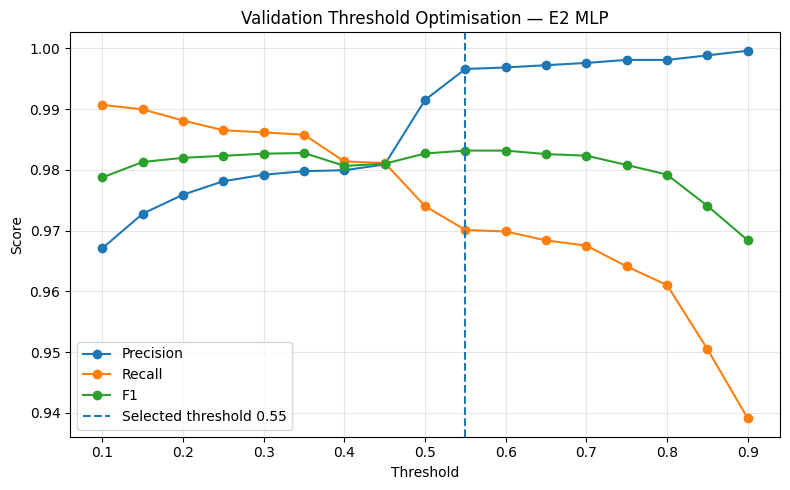

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99     21841
      Attack       1.00      0.97      0.98      8159

    accuracy                           0.99     30000
   macro avg       0.99      0.99      0.99     30000
weighted avg       0.99      0.99      0.99     30000

Confusion matrix: [[21822    19]
 [  237  7922]]


In [15]:
import matplotlib.pyplot as plt
ax=threshold_df.plot(x='Threshold',y=['Precision','Recall','F1'],marker='o',figsize=(8,5))
ax.axvline(best_threshold,linestyle='--',label=f'Selected threshold {best_threshold:.2f}')
ax.set(title='Validation Threshold Optimisation — E2 MLP',ylabel='Score')
ax.grid(alpha=.3);ax.legend();plt.tight_layout()
plt.savefig(OUT/'threshold_optimisation.png',dpi=200);plt.show()
y_pred_e3=(y_prob_e2>=best_threshold).astype(int)
print(classification_report(y_test,y_pred_e3,target_names=['Normal','Attack']))
print('Confusion matrix:',confusion_matrix(y_test,y_pred_e3))

## A6 — E1 vs E2 vs E3: unified results (MLO 2)
E3 uses the same model as E2; `Training_Seconds` records **model training only** and is identical for E2 and E3. Use validation for choices; report test only once for final assessment.

### 3.13. Comparative analysis of experiments E1, E2, and E3 (MLO 2)

Following the individual evaluation of the experiments, a consolidated comparison was conducted between architectures E1 and E2, as well as the threshold adjustment applied in experiment E3. The analysis considers predictive performance, attack detection capability, and training time, in accordance with the criteria established in MLO 2.

The table below presents the consolidated results for the three experiments:

| Metric | E1 | E2 | E3 |
|---|---:|---:|---:|
| Accuracy | 0.9775 | 0.9912 | 0.9915 |
| Precision | 0.9915 | 0.9928 | 0.9976 |
| Recall | 0.9252 | 0.9746 | 0.9710 |
| F1-score | 0.9572 | 0.9836 | 0.9841 |
| ROC-AUC | 0.9954 | 0.9991 | 0.9991 |
| Training time (s) | 15.47 | 38.47 | 38.47 |
| False negatives | 610 | 207 | 237 |
| False positives | 65 | 58 | 19 |

The results indicate that architecture **E2 showed a significant improvement over E1**, increasing the recall from 0.9252 to 0.9746 and reducing false negatives from 610 to 207. However, this improvement was accompanied by an increase in training time—from approximately 15.47 to 38.47 seconds—highlighting the trade-off between predictive performance and computational cost. Experiment E3 yielded the highest F1-score (0.9841) and the highest precision (0.9976), while also reducing false positives to 19. However, its recall was slightly lower than that of E2, resulting in 237 undetected attacks, compared to 207 in E2.

It is important to note that E3 uses the same neural network trained for E2, with the only modification being a change in the classification threshold from 0.50 to 0.55. Consequently, the training time reported for E3 corresponds to the same training process used for E2, incurring no additional cost.

The comparison demonstrates that E2 provides the best results for identifying attacks, whereas E3 prioritizes the reduction of false alarms and achieves the highest F1-score in the consolidated table. The choice between these configurations depends on the operational requirements of the IIoT application—specifically, the impact associated with false negatives.

Thus, these experiments satisfy MLO 2 by enabling the selection and evaluation of neural network architectures while simultaneously considering predictive performance, computational complexity, and the security requirements of the application.

In [16]:
def metric_row(name, y_pred, y_prob, train_s, threshold):
    return {'Experiment':name,'Threshold':threshold,'Accuracy':accuracy_score(y_test,y_pred),
            'Precision':precision_score(y_test,y_pred,zero_division=0),
            'Recall':recall_score(y_test,y_pred,zero_division=0),
            'F1':f1_score(y_test,y_pred,zero_division=0),
            'ROC_AUC':roc_auc_score(y_test,y_prob),'Training_Seconds':train_s,
            'False_Negatives':int(confusion_matrix(y_test,y_pred)[1,0]),
            'False_Positives':int(confusion_matrix(y_test,y_pred)[0,1])}
model_results=pd.DataFrame([
    metric_row('E1 Baseline MLP',y_pred_e1,y_prob_e1,training_time_e1,.5),
    metric_row('E2 MLP with Dropout',y_pred_e2,y_prob_e2,training_time_e2,.5),
    metric_row('E3 E2 with tuned threshold',y_pred_e3,y_prob_e2,training_time_e2,best_threshold)])
display(model_results.round(4))
model_results.to_csv(OUT/'neural_network_results.csv',index=False)

,Experiment,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Training_Seconds,False_Negatives,False_Positives
0,E1 Baseline MLP,0.50,0.9775,0.9915,0.9252,0.9572,0.9954,15.4666,610,65
1,E2 MLP with Dropout,0.50,0.9912,0.9928,0.9746,0.9836,0.9991,38.4668,207,58
2,E3 E2 with tuned threshold,0.55,0.9915,0.9976,0.9710,0.9841,0.9991,38.4668,237,19


### 3.15. Comparative visualization of the performance of experiments E1, E2, and E3 (MLO 2)

To complement the quantitative analysis presented in Section 3.14, a bar chart was created to compare the *precision*, *recall*, and *F1-score* metrics across the three experiments. This representation allows for the visualization of performance differences between the initial architecture (E1), the improved architecture (E2), and model E3, which features an adjusted classification threshold.

The chart highlights a significant improvement from E1 to E2, particularly in *recall*, which increased from **0.9252 to 0.9746**, indicating a greater capacity to identify malicious records. The *F1-score* also rose from 0.9572 to 0.9836, demonstrating a better balance between *precision* and *recall*.

In E3, *precision* increased to **0.9976**, accompanied by a slight reduction in *recall* to 0.9710. The *F1-score* reached 0.9841, which is marginally higher than that of E2. This behavior confirms the trade-off—discussed earlier—between reducing false alarms and maintaining the ability to identify attacks.

Therefore, the visualization reinforces that **E2 yielded the highest *recall*, while E3 achieved the highest *precision* and the highest *F1-score***. These results demonstrate that the selection of the most appropriate configuration depends on the application's priorities: whether to maximize attack detection or to minimize the occurrence of false positives.

This graphical analysis complements MLO 2 by providing a visual representation of how architectural modifications and adjustments to the classification threshold affect the predictive performance of the models.

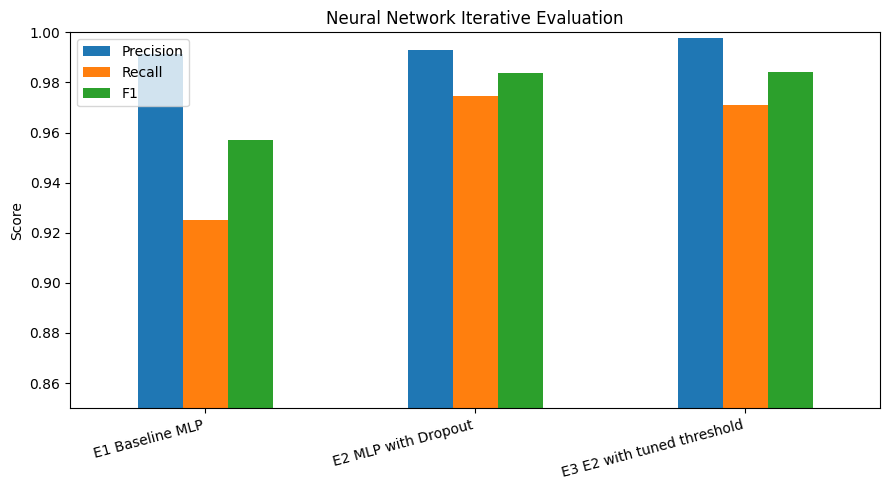

In [17]:
ax=model_results.plot(x='Experiment',y=['Precision','Recall','F1'],kind='bar',figsize=(9,5),ylim=(0.85,1.0))
ax.set(title='Neural Network Iterative Evaluation',ylabel='Score',xlabel='')
plt.xticks(rotation=15,ha='right');plt.tight_layout()
plt.savefig(OUT/'neural_network_comparison.png',dpi=200);plt.show()

## A7 — Critical evaluation and MLO mapping
**MLO 1:** Compare MLP, CNN, recurrent models, autoencoders and Transformers in the literature. Explain assumptions, suitability for tabular vs temporal data, complexity and explainability. **MLO 2:** Justify MLP for numeric tabular features, stratified splitting, training-only scaling, F1/recall for attacks, and validation-only threshold selection.

**Previously observed results (historical, not guaranteed to reproduce):** E1 F1 0.9537, ROC-AUC 0.9909, ~30.9s; E2 F1 0.9557, ROC-AUC 0.9937, ~93.05s; E3 threshold 0.35, F1 0.9651, recall 0.9539. Differences may arise because this standalone notebook explicitly standardises the split and preprocessing.

**Limitations:** record-level random split may leak correlated sessions; E2 changes depth, width and dropout together; class imbalance; no unseen-site or temporal holdout; no distributed NN training; runtime depends on Colab hardware.

In [18]:
print('Results saved to:',OUT)
print(''.join(str(p) for p in sorted(OUT.glob('*'))))

Results saved to: /content/iiot_ca_results
/content/iiot_ca_results/neural_network_comparison.png/content/iiot_ca_results/neural_network_results.csv/content/iiot_ca_results/threshold_optimisation.png/content/iiot_ca_results/threshold_validation.csv
